## Gradient Boosting Model

## Gradient Boosting

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV



# Search current working directory and Downloads folder for the data folder
locations = [Path.cwd(), Path.home() / "Downloads" / "Tumor_Surface_Checkpoint1_Outputs", Path.home() / "Downloads"]
data_folder = next((p for p in locations if all((p / f"checkpoint1_{s}.csv").exists() for s in ("train", "validation"))), None)

In [2]:
# Load the training and validation data, and set up the feature and target columns
train = pd.read_csv(data_folder / "checkpoint1_train.csv").set_index("sample")
val = pd.read_csv(data_folder / "checkpoint1_validation.csv").set_index("sample")
feature_cols = ["mean_expression", "enrichment", "expression_variability", "amplification_frequency"]
target_col = "dependency_score"

# Set up the training and validation data, and create a surface mask for the validation set
X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
surface_mask = val["is_surface"].to_numpy(dtype=bool)

print("Train:", len(train), "(surface:", int(train.is_surface.sum()), ")")
print("Validation:", len(val), "(surface:", int(surface_mask.sum()), ")")
print("No test set accessed.")

Train: 1400 (surface: 175 )
Validation: 300 (surface: 38 )
No test set accessed.


In [7]:
# Build the model using a median imputer and a Gradient Boosting Regressor with the specified hyperparameters
def build_model(config, features=feature_cols):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("gb", GradientBoostingRegressor(loss="squared_error", random_state=42, **config))
    ])

# Score the model's predictions using MAE, RMSE, R2, and Spearman correlation
def score(y, pred):
    y = np.asarray(y); pred = np.asarray(pred)

    # Calculate Spearman correlation only if there are at least 3 samples
    spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan

    return {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),  "R2": r2_score(y, pred), "Spearman": spearman_rho}

from sklearn.model_selection import GridSearchCV

# Define the hyperparameter combinations
param_grid = {
    "gb__n_estimators": [150, 200, 300, 500, 1000],
    "gb__learning_rate": [0.01, 0.001, 0.005, 0.05, 0.10],
    "gb__max_depth": [2, 3, 4],
    "gb__min_samples_leaf": [5, 10, 15, 20]
}

# Build the Gradient Boosting pipeline
model = build_model({})

# Perform 5-fold cross-validation
grid_search = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_mean_absolute_error", n_jobs=-1,
    verbose=1, return_train_score=True
)

# Fit using training data only
grid_search.fit(X_train, y_train)

# Retrieve best model and parameters
best_model = grid_search.best_estimator_

best_config = {
key.replace("gb__", ""): value
    for key, value in grid_search.best_params_.items()
}

print("Best hyperparameters:", best_config)
print("Best CV MAE:", -grid_search.best_score_)

# Display hyperparameter tuning results
tuning = pd.DataFrame(grid_search.cv_results_)

tuning = tuning[["param_gb__n_estimators", "param_gb__learning_rate",
    "param_gb__max_depth", "param_gb__min_samples_leaf",
    "mean_test_score", "std_test_score", "mean_train_score"
]].copy()

tuning.columns = [
    "n_estimators", "learning_rate", "max_depth",
    "min_samples_leaf", "CV_MAE", "CV_MAE_std",
    "Train_MAE"
]

tuning["CV_MAE"] = -tuning["CV_MAE"]
tuning["Train_MAE"] = -tuning["Train_MAE"]

tuning = tuning.sort_values("CV_MAE")
display(tuning.head(10))

# Evaluate selected model on validation data
val_predictions = best_model.predict(X_val)

print("Validation performance:")
print(score(y_val, val_predictions))

Fitting 5 folds for each of 300 candidates, totalling 1500 fits
Best hyperparameters: {'learning_rate': 0.005, 'max_depth': 4, 'min_samples_leaf': 15, 'n_estimators': 300}
Best CV MAE: 0.21742320304688997


,n_estimators,learning_rate,max_depth,min_samples_leaf,CV_MAE,CV_MAE_std,Train_MAE
172,300,0.005,4,15,0.217423,0.014060,0.197541
50,150,0.010,4,15,0.217427,0.014134,0.197521
51,200,0.010,4,15,0.217578,0.013811,0.192814
45,150,0.010,4,10,0.218086,0.013585,0.194995
36,200,0.010,3,20,0.218145,0.013290,0.202394
167,300,0.005,4,10,0.218161,0.013564,0.194927
31,200,0.010,3,15,0.218259,0.013531,0.201628
158,500,0.005,3,20,0.218335,0.012835,0.199926
173,500,0.005,4,15,0.218449,0.013345,0.189246
56,200,0.010,4,20,0.218512,0.012846,0.195129


Validation performance:
{'MAE': 0.20283430829297114, 'RMSE': np.float64(0.3592622730825777), 'R2': 0.13678032679560004, 'Spearman': np.float64(0.40169741299532163)}


In [6]:
# Evaluate the best model and a constant baseline model on the validation set
constant = DummyRegressor(strategy="mean").fit(X_train, y_train)
constant_pred = constant.predict(X_val)
metric_rows = []

# Evaluate both the constant baseline model and the best Gradient Boosting model
for model_name, pred in [("Constant", constant_pred), ("Gradient boosting", val_predictions)]:
    for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
        metric_rows.append({"Model": model_name, "Subset": subset, "N": int(mask.sum()),
                            **score(y_val.to_numpy()[mask], pred[mask])})

metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))

/var/folders/zg/747my4dd0dd82wrv7jq9djjm0000gn/T/ipykernel_21996/3502053020.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan
/var/folders/zg/747my4dd0dd82wrv7jq9djjm0000gn/T/ipykernel_21996/3502053020.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho = spearmanr(y, pred).statistic if len(y) >= 3 and np.std(y) > 0 and np.std(pred) > 0 else np.nan


,Model,Subset,N,MAE,RMSE,R2,Spearman
0,Constant,Overall,300,0.2355,0.3874,-0.0037,NaN
1,Constant,Surface,38,0.1970,0.2372,-0.1790,NaN
2,Gradient boosting,Overall,300,0.2028,0.3593,0.1368,0.4017
3,Gradient boosting,Surface,38,0.1730,0.2370,-0.1774,0.4562


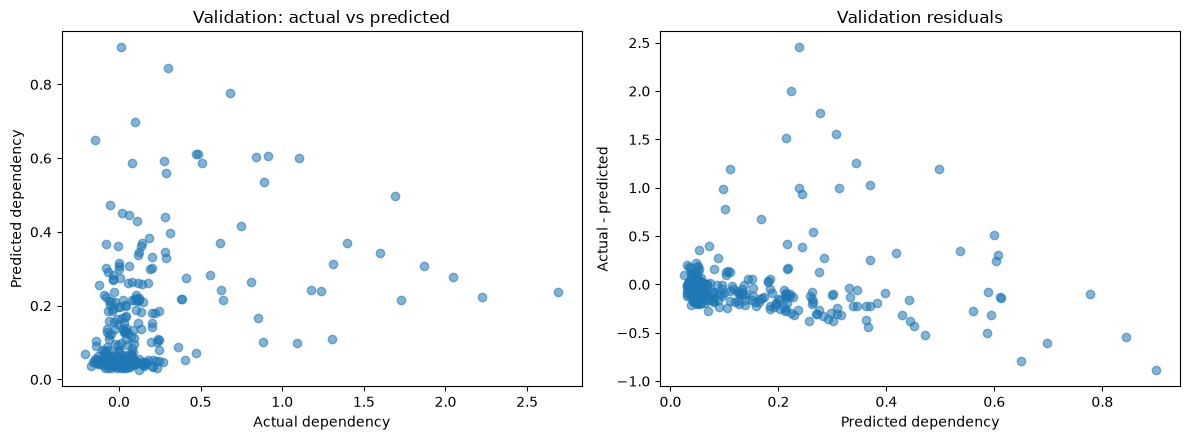

,feature,tree_importance
0,mean_expression,0.350012
2,expression_variability,0.329942
1,enrichment,0.269439
3,amplification_frequency,0.050608


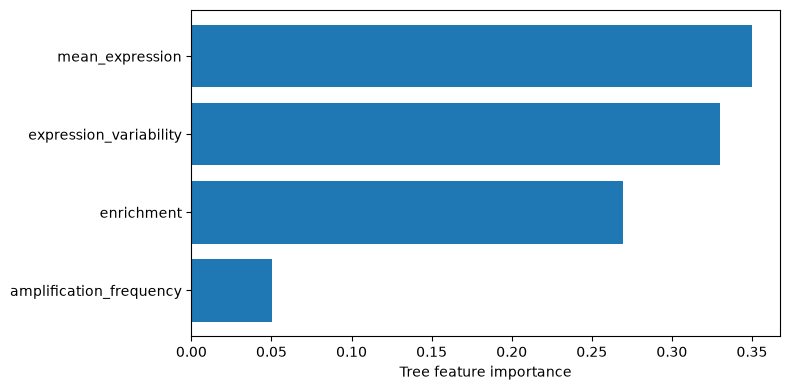

,feature,MAE_increase_mean,MAE_increase_sd
1,enrichment,0.01306,0.00376
2,expression_variability,0.00974,0.00361
0,mean_expression,0.00881,0.00508
3,amplification_frequency,-0.00012,0.00094


In [8]:
# Plot the actual vs predicted dependency scores and the residuals for the best model on the validation set
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_val, val_predictions, alpha=0.55)
axes[0].set(xlabel="Actual dependency", ylabel="Predicted dependency", title="Validation: actual vs predicted")
residuals = y_val.to_numpy() - val_predictions

axes[1].scatter(val_predictions, residuals, alpha=0.55)
axes[1].set(xlabel="Predicted dependency", ylabel="Actual - predicted", title="Validation residuals")

plt.tight_layout(); plt.show()

importance = pd.DataFrame({"feature": feature_cols, "tree_importance": best_model.named_steps["gb"].feature_importances_}).sort_values("tree_importance", ascending=False)
display(importance)

plt.figure(figsize=(8, 4)); plt.barh(importance.feature[::-1], importance.tree_importance[::-1]); plt.xlabel("Tree feature importance"); plt.tight_layout(); plt.show()

permutation = permutation_importance(best_model, X_val, y_val, n_repeats=20, random_state=42,
                              scoring="neg_mean_absolute_error")

perm_df = pd.DataFrame({"feature": feature_cols, "MAE_increase_mean": permutation.importances_mean,
                        "MAE_increase_sd": permutation.importances_std}).sort_values("MAE_increase_mean", ascending=False)

display(perm_df.round(5))

,predicted_dependency,dependency_score,absolute_error,amplification_frequency,mean_expression
sample,,,,,
ZDHHC5,0.900155,0.011439,0.888716,0.005814,11.444761
SLC3A2,0.611875,0.473682,0.138193,0.003876,11.681265
SNAP23,0.587578,0.505550,0.082028,0.000000,10.504822
PFDN1,0.416992,0.746865,0.329872,0.003876,10.187203
MARCKSL1,0.382790,0.186268,0.196522,0.007752,11.696356
EPN1,0.362101,-0.004669,0.366770,0.007752,11.310908
APPL1,0.316671,-0.000687,0.317358,0.001938,10.083684
LRRC45,0.298961,0.189501,0.109460,0.034884,8.814010
TSPAN15,0.271985,-0.034055,0.306040,0.007752,10.695355


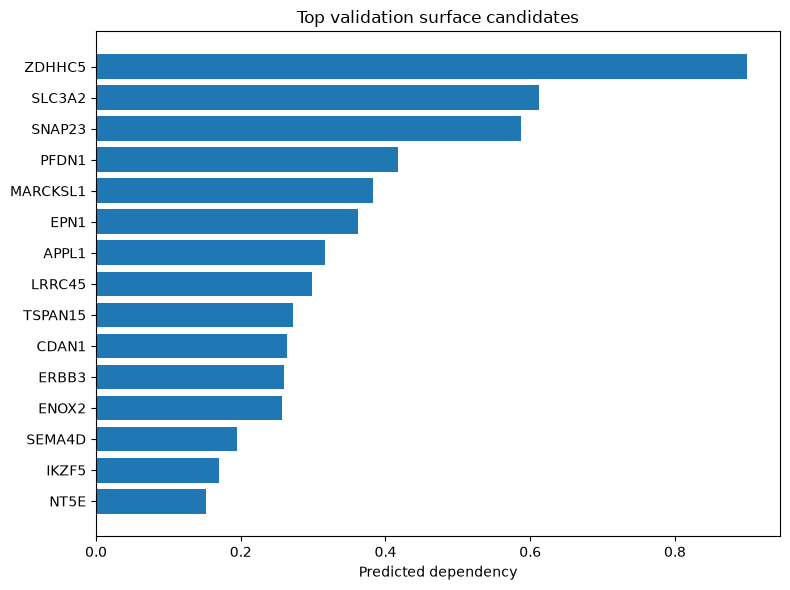

In [9]:
# Rank the validation samples by predicted dependency score, and display the top surface candidates
ranking = val.copy()
ranking["predicted_dependency"] = val_predictions
ranking["absolute_error"] = np.abs(y_val.to_numpy() - val_predictions)
surface_ranking = ranking.loc[ranking.is_surface].sort_values("predicted_dependency", ascending=False)

display(surface_ranking[["predicted_dependency", "dependency_score", "absolute_error", "amplification_frequency", "mean_expression"]].head(20))
top = surface_ranking.head(15).iloc[::-1]

plt.figure(figsize=(8, 6)); plt.barh(top.index, top.predicted_dependency)
plt.xlabel("Predicted dependency"); plt.title("Top validation surface candidates"); plt.tight_layout(); plt.show()

In [11]:

ablation_rows = []

# Evaluate the model performance with all features and without the amplification frequency feature
for feature_group, cols in [
    ("All four", feature_cols),
    ("No amplification", [
        c for c in feature_cols
        if c != "amplification_frequency"
    ])
]:
    search = GridSearchCV(estimator=build_model({}),
        param_grid=param_grid, cv=5,
        scoring="neg_mean_absolute_error", n_jobs=-1)

    # Tune using only the training data
    search.fit(X_train[cols], y_train)

    # Evaluate the best model on validation data
    model_pred = search.best_estimator_.predict(X_val[cols])

    ablation_rows.append({
        "Feature set": feature_group,
        "CV MAE": -search.best_score_,
        "Validation MAE": mean_absolute_error(y_val, model_pred),
        "Surface MAE": mean_absolute_error(
            y_val.to_numpy()[surface_mask],
            model_pred[surface_mask]
        ),
        "Spearman": score(y_val, model_pred)["Spearman"],
        "Best Parameters": search.best_params_
    })

ablation_best = pd.DataFrame(ablation_rows)
display(ablation_best)

,Feature set,CV MAE,Validation MAE,Surface MAE,Spearman,Best Parameters
0,All four,0.217423,0.202834,0.172991,0.401697,"{'gb__learning_rate': 0.005, 'gb__max_depth': ..."
1,No amplification,0.218006,0.204111,0.174069,0.412790,"{'gb__learning_rate': 0.01, 'gb__max_depth': 4..."


In [12]:
random_generator = np.random.default_rng(42)
bootstrap_rows = []

# For each subset (Overall and Surface), perform bootstrap resampling to estimate the confidence intervals for MAE and Spearman correlation
for subset, mask in [("Overall", np.ones(len(val), dtype=bool)), ("Surface", surface_mask)]:
    yt = y_val.to_numpy()[mask]; yp = val_predictions[mask]
    # Perform 1000 bootstrap resamples to calculate MAE and Spearman correlation for each resample
    for _ in range(1000):
        idx = random_generator.integers(0, len(yt), len(yt))
        bootstrap_rows.append({"Subset": subset, "MAE": mean_absolute_error(yt[idx], yp[idx]),
            "Spearman": score(yt[idx], yp[idx])["Spearman"]})

# Calculate the 2.5% and 97.5% quantiles for MAE and Spearman correlation for each subset to estimate the confidence intervals
boot = pd.DataFrame(bootstrap_rows)
confidence_intervals_rows = []
for subset, subset_group in boot.groupby("Subset"):
    for metric in ["MAE", "Spearman"]:
        confidence_intervals_rows.append({"Subset": subset, "Metric": metric,
                        "2.5%": subset_group[metric].quantile(.025), "97.5%": subset_group[metric].quantile(.975)})

display(pd.DataFrame(confidence_intervals_rows).round(4))

,Subset,Metric,2.5%,97.5%
0,Overall,MAE,0.1721,0.2401
1,Overall,Spearman,0.3042,0.4999
2,Surface,MAE,0.1247,0.2284
3,Surface,Spearman,0.1575,0.6829
